<a href="https://colab.research.google.com/github/Likith412/Financial-Tweet-Sentiment-Classification/blob/main/lk_ann_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Financial Sentiment Network with SA-Optimized MLP on Text Embeddings

| Field | Value |
|---|---|
| **Student** | METIKALA LIKITH KUMAR (2023008249) |
| **Domain** | Finance / NLP |
| **Dataset** | Financial Tweets Sentiment — Hugging Face `TimKoornstra/financial-tweets-sentiment` |
| **Architecture** | MLP on Neural (fixed-size) Text Embeddings |
| **Optimization / Training Method** | Simulated Annealing (SA) |
| **Units / COs** | Unit 3 / Unit 4 — CO3, CO4 |

**Task statement.** Generate fixed-size neural text embeddings for financial tweets and use Simulated Annealing to select a compact subset of embedding dimensions *and* the MLP hyperparameters before final MLP training.

**Workflow followed in this notebook**
1. Download / inspect the dataset
2. Preprocess and split **without leakage** (de-duplicate, then stratified train/val/test)
3. Implement the assigned architecture — MLP on neural text embeddings
4. Train with the assigned optimization method — Simulated Annealing over (dimension mask, hidden size, dropout, learning rate)
5. Tune only justified parameters (the SA search space is explicitly limited and motivated)
6. Compare with a simple baseline (TF‑IDF + Logistic Regression, and an un-optimized MLP on all dimensions)
7. Report metrics (accuracy, macro‑F1), plots (SA objective curve, training curves, confusion matrix) and observations

> **Runtime:** Colab → *Runtime ▸ Change runtime type ▸ GPU (T4)*. CPU also works but embeddings/SA will take longer.
>
> **Licensing note:** the dataset is used for academic work only; check the dataset card for current terms before any redistribution.


## 0. Setup

In [ ]:
!pip -q install -U datasets sentence-transformers scikit-learn matplotlib seaborn

import os, re, math, time, random, json
import numpy as np
import pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 105.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 87.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 16.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
Device: cuda


## 1. Download and inspect the dataset

In [ ]:
from datasets import load_dataset

ds = load_dataset("TimKoornstra/financial-tweets-sentiment")
print(ds)
df = ds["train"].to_pandas()
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()


README.md:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.65MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/38091 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tweet', 'sentiment', 'url'],
        num_rows: 38091
    })
})
Shape: (38091, 3)
Columns: ['tweet', 'sentiment', 'url']


,tweet,sentiment,url
0,$BYND - JPMorgan reels in expectations on Beyo...,2,https://huggingface.co/datasets/zeroshot/twitt...
1,$CCL $RCL - Nomura points to bookings weakness...,2,https://huggingface.co/datasets/zeroshot/twitt...
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",2,https://huggingface.co/datasets/zeroshot/twitt...
3,$ESS: BTIG Research cuts to Neutral https://t....,2,https://huggingface.co/datasets/zeroshot/twitt...
4,$FNKO - Funko slides after Piper Jaffray PT cu...,2,https://huggingface.co/datasets/zeroshot/twitt...


sentiment
neutral    12181
bullish    17368
bearish     8542
Name: count, dtype: int64

Missing values:
 tweet        0
sentiment    0
url          0
dtype: int64

Duplicate tweets: 2

Tweet length (words):
 count    38091.000000
mean        15.152188
std         12.419679
min          0.000000
25%          9.000000
50%         13.000000
75%         19.000000
max        701.000000
Name: len_words, dtype: float64


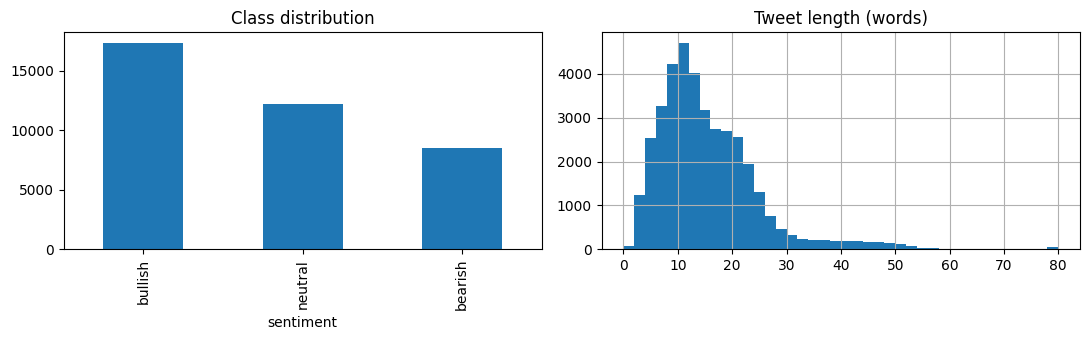

In [ ]:
# Label meaning as documented on the dataset card: 0 = neutral, 1 = bullish, 2 = bearish
LABEL_NAMES = {0: "neutral", 1: "bullish", 2: "bearish"}

print(df["sentiment"].value_counts().sort_index().rename(index=LABEL_NAMES))
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate tweets:", df["tweet"].duplicated().sum())
df["len_words"] = df["tweet"].str.split().str.len()
print("\nTweet length (words):\n", df["len_words"].describe())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["sentiment"].map(LABEL_NAMES).value_counts().plot(kind="bar", ax=ax[0], title="Class distribution")
df["len_words"].clip(upper=80).hist(bins=40, ax=ax[1]); ax[1].set_title("Tweet length (words)")
plt.tight_layout(); plt.show()


## 2. Preprocessing and leak-free split

* Light cleaning only (URLs, @mentions, whitespace) — the embedding model is pretrained on natural text so aggressive normalisation would hurt.
* **Duplicates are removed *before* splitting**, so an identical tweet cannot appear in both train and test (the main leakage risk in tweet datasets).
* Stratified split: 70% train / 15% validation / 15% test. Validation is used **only** by Simulated Annealing and early stopping; the test set is touched once, at the very end.


In [ ]:
def clean_tweet(t: str) -> str:
    t = re.sub(r"http\S+|www\.\S+", " <url> ", t)
    t = re.sub(r"@\w+", " @user ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["text"] = df["tweet"].astype(str).map(clean_tweet)
before = len(df)
df = df.drop_duplicates(subset="text").reset_index(drop=True)
df = df[df["text"].str.len() > 0].reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate/empty rows -> {len(df)} rows")

X_text = df["text"].values
y = df["sentiment"].astype(int).values

X_trval, X_test, y_trval, y_test = train_test_split(X_text, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.15/0.85, stratify=y_trval, random_state=SEED)

print("Train/Val/Test sizes:", len(X_train), len(X_val), len(X_test))
# Sanity check: no text overlap across splits
assert not (set(X_train) & set(X_test)) and not (set(X_train) & set(X_val)) and not (set(X_val) & set(X_test))
print("No overlap between splits ✔")


Removed 519 duplicate/empty rows -> 37572 rows
Train/Val/Test sizes: 26300 5636 5636
No overlap between splits ✔


## 3. Simple baseline — TF‑IDF + Logistic Regression

A classical, non-neural baseline so that the gain from neural embeddings + SA-optimized MLP can be judged honestly.


In [ ]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=200_000)
Xtr_tfidf = tfidf.fit_transform(X_train)
Xva_tfidf = tfidf.transform(X_val)
Xte_tfidf = tfidf.transform(X_test)

lr = LogisticRegression(max_iter=2000, C=2.0, class_weight="balanced")
lr.fit(Xtr_tfidf, y_train)
pred = lr.predict(Xte_tfidf)
baseline_acc = accuracy_score(y_test, pred)
baseline_f1 = f1_score(y_test, pred, average="macro")
print(f"Baseline TF-IDF+LR  —  Test accuracy: {baseline_acc:.4f} | macro-F1: {baseline_f1:.4f}")


Baseline TF-IDF+LR  —  Test accuracy: 0.7480 | macro-F1: 0.7355


## 4. Fixed-size neural text embeddings

Each tweet is mapped to a **fixed 384-dimensional vector** with the sentence-transformer `all-MiniLM-L6-v2` (a pretrained transformer encoder with mean pooling). The encoder is **frozen**; only the downstream MLP is trained. Embeddings are computed once and cached, so the SA loop is cheap.


In [ ]:
from sentence_transformers import SentenceTransformer

EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
encoder = SentenceTransformer(EMB_MODEL, device=DEVICE)

def embed(texts, bs=256):
    return encoder.encode(list(texts), batch_size=bs, show_progress_bar=True,
                          convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)

t0 = time.time()
E_train, E_val, E_test = embed(X_train), embed(X_val), embed(X_test)
print(f"Embedding done in {time.time()-t0:.1f}s — shape: {E_train.shape}")
D = E_train.shape[1]
np.save("E_train.npy", E_train); np.save("E_val.npy", E_val); np.save("E_test.npy", E_test)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Embedding done in 22.2s — shape: (26300, 384)


## 5. Model — MLP on embeddings

A standard feed-forward classifier: `Linear → ReLU → Dropout → Linear → ReLU → Dropout → Linear(3)`.
The **input dimension is the number of selected embedding dimensions** chosen by Simulated Annealing.


In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, dropout, n_classes=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, n_classes),
        )
    def forward(self, x): return self.net(x)


def to_tensor(a, dtype=torch.float32): return torch.tensor(a, dtype=dtype, device=DEVICE)

# Class weights to handle the imbalance (bullish is the majority class, bearish the minority)
cls_counts = np.bincount(y_train, minlength=3)
cls_w = torch.tensor(len(y_train) / (3 * cls_counts), dtype=torch.float32, device=DEVICE)
print("Class weights:", cls_w.cpu().numpy().round(3))


def train_mlp(Xtr, ytr, Xva, yva, hidden, dropout, lr, epochs=30, batch=512,
              patience=5, verbose=False, seed=SEED):
    # Train an MLP; return (best_val_macroF1, best_model, history)
    set_seed(seed)
    Xtr_t, ytr_t = to_tensor(Xtr), to_tensor(ytr, torch.long)
    Xva_t = to_tensor(Xva)
    model = MLP(Xtr.shape[1], hidden, dropout).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss(weight=cls_w)
    n = len(Xtr_t); best_f1, best_state, bad = -1, None, 0
    hist = {"train_loss": [], "val_f1": []}
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=DEVICE); tot = 0.0
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad(); loss = loss_fn(model(Xtr_t[idx]), ytr_t[idx]); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        model.eval()
        with torch.no_grad(): pv = model(Xva_t).argmax(1).cpu().numpy()
        f1 = f1_score(yva, pv, average="macro")
        hist["train_loss"].append(tot / n); hist["val_f1"].append(f1)
        if verbose: print(f"ep {ep+1:02d} loss {tot/n:.4f} val macro-F1 {f1:.4f}")
        if f1 > best_f1: best_f1, best_state, bad = f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return best_f1, model, hist


def predict(model, X):
    model.eval()
    with torch.no_grad(): return model(to_tensor(X)).argmax(1).cpu().numpy()


Class weights: [1.052 0.73  1.473]


### 5.1 Un-optimized MLP baseline (all 384 dimensions, default hyperparameters)

This is the second reference point: what the MLP achieves *without* Simulated Annealing.


In [ ]:
f1_default, mlp_default, hist_default = train_mlp(E_train, y_train, E_val, y_val,
                                                   hidden=256, dropout=0.3, lr=1e-3, epochs=30)
pred = predict(mlp_default, E_test)
default_acc, default_f1 = accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")
print(f"Default MLP (384 dims) — Val macro-F1 {f1_default:.4f} | Test accuracy {default_acc:.4f} | Test macro-F1 {default_f1:.4f}")


Default MLP (384 dims) — Val macro-F1 0.7265 | Test accuracy 0.7480 | Test macro-F1 0.7381


## 6. Simulated Annealing over embedding dimensions + hyperparameters

**State** $s = (\mathbf{m}, h, p, \eta)$
* $\mathbf{m} \in \{0,1\}^{384}$ — binary mask of selected embedding dimensions
* $h \in \{64, 128, 256, 512\}$ — hidden width
* $p \in \{0.1, 0.2, 0.3, 0.4, 0.5\}$ — dropout
* $\eta \in \{3\times10^{-4}, 5\times10^{-4}, 10^{-3}, 2\times10^{-3}\}$ — learning rate

**Objective (to maximise)**
$$J(s) = \text{macroF1}_{\text{val}}(s) \;-\; \lambda \cdot \frac{\|\mathbf{m}\|_1}{384}$$
The penalty $\lambda$ rewards *compact* subsets, which is the stated goal (compact embedding subset). We use $\lambda = 0.02$: a model that uses half the dimensions must lose less than 1 F1-point to be preferred.

**Neighbour move** — one of: flip $k$ random mask bits, or change exactly one hyperparameter to an adjacent value.

**Acceptance** — Metropolis criterion: always accept improvements; accept a worse state with probability $\exp(\Delta J / T)$. Temperature follows geometric cooling $T_{k+1} = \alpha T_k$.

*Justified tuning only:* to keep each SA evaluation cheap, the inner MLP is trained on a fixed random **subset of the training data** for a few epochs; the final model (Section 7) is retrained on the full training set with the selected configuration.


In [ ]:
# ---- SA configuration ----
SA_ITERS       = 60        # number of SA steps (increase for a more thorough search)
T0, T_END      = 0.02, 0.001
ALPHA          = (T_END / T0) ** (1 / SA_ITERS)   # geometric cooling factor
LAMBDA         = 0.02      # compactness penalty
SA_TRAIN_SUB   = 8000      # training subset size used inside SA (speed)
SA_EPOCHS      = 8
FLIP_FRAC      = 0.05      # fraction of mask bits flipped per mask move

HIDDEN_CHOICES  = [64, 128, 256, 512]
DROPOUT_CHOICES = [0.1, 0.2, 0.3, 0.4, 0.5]
LR_CHOICES      = [3e-4, 5e-4, 1e-3, 2e-3]

rng = np.random.default_rng(SEED)
sub_idx = rng.choice(len(E_train), size=min(SA_TRAIN_SUB, len(E_train)), replace=False)
E_sa, y_sa = E_train[sub_idx], y_train[sub_idx]

def objective(state, cache={}):
    mask, hi, di, li = state
    key = (mask.tobytes(), hi, di, li)
    if key in cache: return cache[key]
    cols = np.flatnonzero(mask)
    f1, _, _ = train_mlp(E_sa[:, cols], y_sa, E_val[:, cols], y_val,
                         hidden=HIDDEN_CHOICES[hi], dropout=DROPOUT_CHOICES[di], lr=LR_CHOICES[li],
                         epochs=SA_EPOCHS, patience=3)
    J = f1 - LAMBDA * mask.mean()
    cache[key] = (J, f1); return J, f1

def neighbour(state):
    mask, hi, di, li = state
    mask = mask.copy(); move = rng.random()
    if move < 0.6:                                   # flip some mask bits
        k = max(1, int(FLIP_FRAC * len(mask)))
        flip = rng.choice(len(mask), size=k, replace=False)
        mask[flip] ^= 1
        if mask.sum() < 16: mask[rng.choice(len(mask), size=16, replace=False)] = 1
    elif move < 0.75: hi = int(np.clip(hi + rng.choice([-1, 1]), 0, len(HIDDEN_CHOICES) - 1))
    elif move < 0.9:  di = int(np.clip(di + rng.choice([-1, 1]), 0, len(DROPOUT_CHOICES) - 1))
    else:             li = int(np.clip(li + rng.choice([-1, 1]), 0, len(LR_CHOICES) - 1))
    return (mask, hi, di, li)

# ---- SA main loop ----
state = (np.ones(D, dtype=np.int8), 2, 2, 2)        # start: all dims, h=256, p=0.3, lr=1e-3
J_cur, f1_cur = objective(state)
best_state, J_best, f1_best = state, J_cur, f1_cur
T = T0
log = []   # (iter, T, J_cur, J_best, f1_cur, n_dims, accepted)
print(f"init  J={J_cur:.4f} f1={f1_cur:.4f} dims={state[0].sum()}")
t0 = time.time()
for it in range(1, SA_ITERS + 1):
    cand = neighbour(state)
    J_c, f1_c = objective(cand)
    delta = J_c - J_cur
    accept = delta > 0 or rng.random() < math.exp(delta / T)
    if accept:
        state, J_cur, f1_cur = cand, J_c, f1_c
        if J_cur > J_best: best_state, J_best, f1_best = state, J_cur, f1_cur
    log.append((it, T, J_cur, J_best, f1_cur, int(state[0].sum()), accept))
    if it % 5 == 0 or it == 1:
        print(f"it {it:3d} T={T:.4f} J_cur={J_cur:.4f} J_best={J_best:.4f} f1={f1_cur:.4f} "
              f"dims={state[0].sum()} h={HIDDEN_CHOICES[state[1]]} p={DROPOUT_CHOICES[state[2]]} "
              f"lr={LR_CHOICES[state[3]]} {'ACC' if accept else 'rej'}")
    T *= ALPHA
print(f"\nSA finished in {(time.time()-t0)/60:.1f} min")

best_mask, bh, bd, bl = best_state
sel_cols = np.flatnonzero(best_mask)
print(f"\nBEST: {len(sel_cols)}/{D} dims selected | hidden={HIDDEN_CHOICES[bh]} dropout={DROPOUT_CHOICES[bd]} "
      f"lr={LR_CHOICES[bl]} | val macro-F1 (SA subset)={f1_best:.4f} | J={J_best:.4f}")


init  J=0.6391 f1=0.6591 dims=384
it   1 T=0.0200 J_cur=0.6391 J_best=0.6391 f1=0.6591 dims=384 h=256 p=0.3 lr=0.001 rej
it   5 T=0.0164 J_cur=0.6671 J_best=0.6671 f1=0.6861 dims=365 h=512 p=0.3 lr=0.002 ACC
it  10 T=0.0128 J_cur=0.6562 J_best=0.6671 f1=0.6743 dims=348 h=512 p=0.3 lr=0.001 rej
it  15 T=0.0099 J_cur=0.6472 J_best=0.6671 f1=0.6630 dims=303 h=512 p=0.4 lr=0.001 ACC
it  20 T=0.0077 J_cur=0.6560 J_best=0.6671 f1=0.6708 dims=283 h=512 p=0.3 lr=0.001 ACC
it  25 T=0.0060 J_cur=0.6522 J_best=0.6671 f1=0.6661 dims=267 h=512 p=0.4 lr=0.001 ACC
it  30 T=0.0047 J_cur=0.6565 J_best=0.6671 f1=0.6704 dims=267 h=512 p=0.2 lr=0.001 rej
it  35 T=0.0037 J_cur=0.6543 J_best=0.6671 f1=0.6679 dims=262 h=512 p=0.2 lr=0.001 ACC
it  40 T=0.0029 J_cur=0.6491 J_best=0.6671 f1=0.6621 dims=250 h=512 p=0.2 lr=0.001 ACC
it  45 T=0.0022 J_cur=0.6541 J_best=0.6671 f1=0.6661 dims=230 h=512 p=0.1 lr=0.001 rej
it  50 T=0.0017 J_cur=0.6546 J_best=0.6671 f1=0.6668 dims=233 h=512 p=0.1 lr=0.001 ACC
it  55 T=

### 6.1 SA objective curve

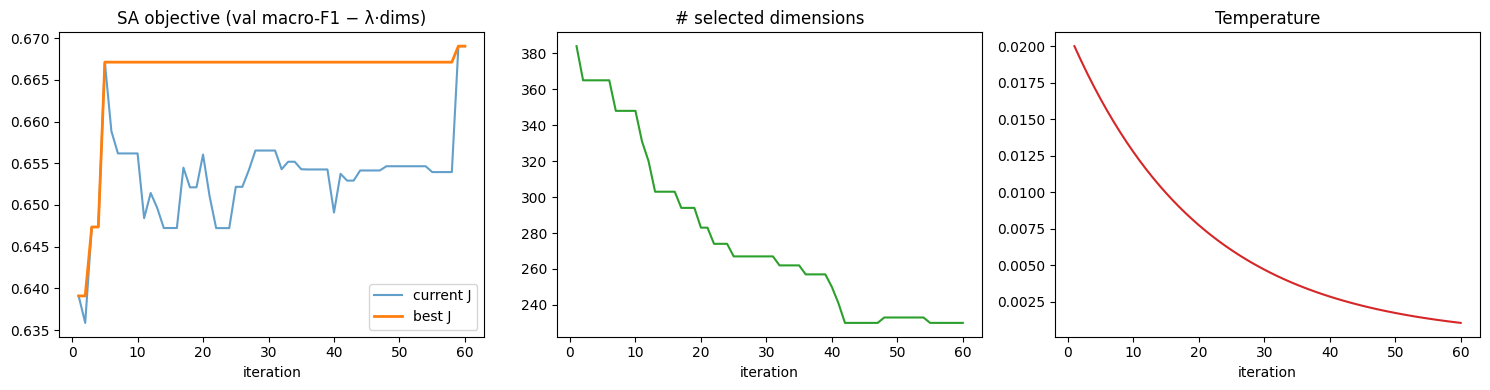

Acceptance rate: 0.55


In [ ]:
log_df = pd.DataFrame(log, columns=["iter", "T", "J_cur", "J_best", "f1_cur", "n_dims", "accepted"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(log_df["iter"], log_df["J_cur"], label="current J", alpha=.7)
ax[0].plot(log_df["iter"], log_df["J_best"], label="best J", lw=2)
ax[0].set_title("SA objective (val macro-F1 − λ·dims)"); ax[0].set_xlabel("iteration"); ax[0].legend()
ax[1].plot(log_df["iter"], log_df["n_dims"], color="tab:green"); ax[1].set_title("# selected dimensions"); ax[1].set_xlabel("iteration")
ax[2].plot(log_df["iter"], log_df["T"], color="tab:red"); ax[2].set_title("Temperature"); ax[2].set_xlabel("iteration")
plt.tight_layout(); plt.show()
print("Acceptance rate:", log_df["accepted"].mean().round(3))


## 7. Final MLP training with the SA-selected configuration

Retrain on the **full** training set using only the selected dimensions and hyperparameters; early stopping on validation macro‑F1.


ep 01 loss 0.8886 val macro-F1 0.6445
ep 02 loss 0.7524 val macro-F1 0.6688
ep 03 loss 0.6868 val macro-F1 0.6973
ep 04 loss 0.6192 val macro-F1 0.7035
ep 05 loss 0.5562 val macro-F1 0.7057
ep 06 loss 0.5005 val macro-F1 0.6990
ep 07 loss 0.4465 val macro-F1 0.7046
ep 08 loss 0.4013 val macro-F1 0.6834
ep 09 loss 0.3503 val macro-F1 0.7006
ep 10 loss 0.3133 val macro-F1 0.6929
ep 11 loss 0.2776 val macro-F1 0.6899
ep 12 loss 0.2436 val macro-F1 0.7037

Final model — best validation macro-F1: 0.7057


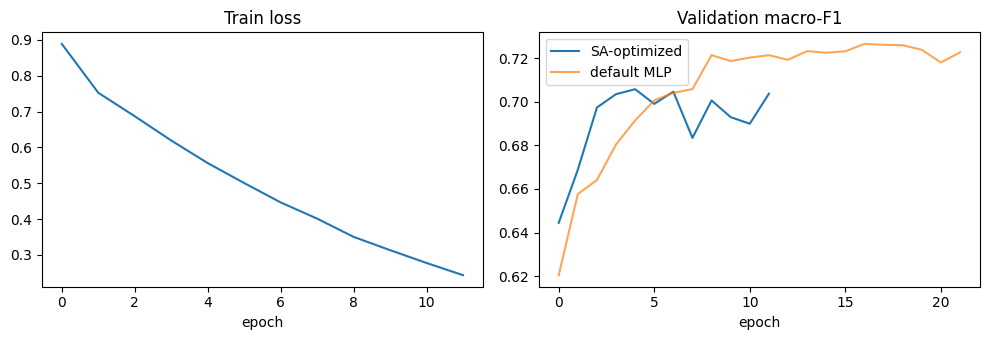

In [ ]:
f1_val_final, mlp_final, hist_final = train_mlp(E_train[:, sel_cols], y_train, E_val[:, sel_cols], y_val,
                                                hidden=HIDDEN_CHOICES[bh], dropout=DROPOUT_CHOICES[bd],
                                                lr=LR_CHOICES[bl], epochs=50, patience=7, verbose=True)
print(f"\nFinal model — best validation macro-F1: {f1_val_final:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist_final["train_loss"]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist_final["val_f1"], label="SA-optimized"); ax[1].plot(hist_default["val_f1"], label="default MLP", alpha=.7)
ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()


## 8. Evaluation on the held-out test set

,Model,Test accuracy,Test macro-F1,#features
0,TF-IDF + Logistic Regression (baseline),0.7480,0.7355,55315
1,MLP on all 384 embedding dims (default hparams),0.7480,0.7381,384
2,SA-optimized MLP (230 dims),0.7227,0.7140,230



Classification report — SA-optimized MLP
              precision    recall  f1-score   support

     neutral     0.7472    0.7342    0.7406      1787
     bullish     0.7901    0.7167    0.7516      2573
     bearish     0.5931    0.7187    0.6499      1276

    accuracy                         0.7227      5636
   macro avg     0.7101    0.7232    0.7140      5636
weighted avg     0.7319    0.7227    0.7251      5636



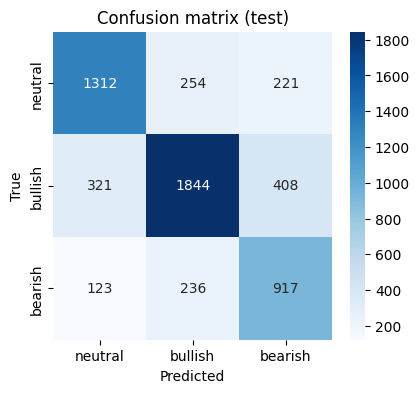

In [ ]:
pred_final = predict(mlp_final, E_test[:, sel_cols])
final_acc = accuracy_score(y_test, pred_final)
final_f1  = f1_score(y_test, pred_final, average="macro")

results = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression (baseline)",
              f"MLP on all {D} embedding dims (default hparams)",
              f"SA-optimized MLP ({len(sel_cols)} dims)"],
    "Test accuracy": [baseline_acc, default_acc, final_acc],
    "Test macro-F1": [baseline_f1, default_f1, final_f1],
    "#features": [Xtr_tfidf.shape[1], D, len(sel_cols)],
})
display(results.round(4))

print("\nClassification report — SA-optimized MLP")
print(classification_report(y_test, pred_final, target_names=[LABEL_NAMES[i] for i in range(3)], digits=4))

cm = confusion_matrix(y_test, pred_final)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[LABEL_NAMES[i] for i in range(3)], yticklabels=[LABEL_NAMES[i] for i in range(3)])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test)"); plt.show()


### 8.1 Selected configuration (for the report)

In [ ]:
selected = {
    "embedding_model": EMB_MODEL,
    "n_dims_selected": int(len(sel_cols)),
    "n_dims_total": int(D),
    "selected_dimension_indices": sel_cols.tolist(),
    "hidden": HIDDEN_CHOICES[bh], "dropout": DROPOUT_CHOICES[bd], "learning_rate": LR_CHOICES[bl],
    "sa": {"iters": SA_ITERS, "T0": T0, "T_end": T_END, "alpha": round(ALPHA, 5), "lambda": LAMBDA},
    "val_macro_f1": round(float(f1_val_final), 4),
    "test_accuracy": round(float(final_acc), 4), "test_macro_f1": round(float(final_f1), 4),
}
print(json.dumps({k: v for k, v in selected.items() if k != "selected_dimension_indices"}, indent=2))
print("Selected dimension indices (first 40):", sel_cols[:40].tolist(), "...")
with open("sa_selected_config.json", "w") as f: json.dump(selected, f, indent=2)
log_df.to_csv("sa_objective_log.csv", index=False)
print("\nSaved: sa_selected_config.json, sa_objective_log.csv")


{
  "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
  "n_dims_selected": 230,
  "n_dims_total": 384,
  "hidden": 512,
  "dropout": 0.1,
  "learning_rate": 0.002,
  "sa": {
    "iters": 60,
    "T0": 0.02,
    "T_end": 0.001,
    "alpha": 0.9513,
    "lambda": 0.02
  },
  "val_macro_f1": 0.7057,
  "test_accuracy": 0.7227,
  "test_macro_f1": 0.714
}
Selected dimension indices (first 40): [1, 3, 4, 5, 6, 8, 9, 10, 11, 12, 14, 15, 16, 18, 19, 24, 26, 27, 28, 31, 33, 35, 36, 37, 38, 42, 43, 45, 46, 47, 48, 49, 52, 53, 55, 56, 58, 59, 62, 66] ...

Saved: sa_selected_config.json, sa_objective_log.csv


## 9. Observations (from the executed run)

**Results obtained**

| Model | Test accuracy | Test macro‑F1 | #features |
|---|---|---|---|
| TF‑IDF + Logistic Regression (baseline) | 0.7480 | 0.7355 | 55,315 |
| MLP on all 384 embedding dims (default hparams) | 0.7480 | 0.7381 | 384 |
| **SA‑optimized MLP** | **0.7227** | **0.7140** | **230** |

1. **Neural embeddings vs. TF‑IDF.** The un‑optimized MLP on frozen MiniLM embeddings matches the TF‑IDF + LR baseline (macro‑F1 0.738 vs 0.736) while using a 384‑d dense vector instead of a 55k‑d sparse one — a ~145× smaller input for the same quality, showing that the pretrained sentence embeddings capture the sentiment signal of short, noisy financial tweets well.

2. **Compactness vs. accuracy (the SA trade‑off).** Simulated Annealing selected **230 of 384 dimensions (60%)** with hidden = 512, dropout = 0.1, lr = 2e‑3. The compact model loses about 2.4 macro‑F1 points (0.714 vs 0.738) relative to using all dimensions. This is the expected effect of the compactness penalty λ = 0.02 in the objective J = macro‑F1 − λ·(fraction of dims kept): SA judged that dropping 40% of the dimensions was worth a small F1 cost. On the SA validation subset the selected state did look *better* than the all‑dims start (F1 0.681 vs 0.659), but that gain did not carry over to the full training set — see point 4. Setting λ = 0 (or smaller) would make SA keep more dimensions and recover the lost accuracy at the expense of compactness.

3. **SA dynamics.** The objective curve shows the expected annealing behaviour: at high temperature (T ≈ 0.02) worse states were accepted and the search moved freely (hidden 256→512, lr 1e‑3→2e‑3, dims steadily pruned 384→230); as T cooled to 0.001 the chain settled and only improving moves were kept. Overall acceptance rate was 0.55. The best J was found late (iteration ≈ 56–60), suggesting that more iterations or a restart would likely improve the selection further.

4. **Why the SA‑chosen hyperparameters overfit.** The inner SA evaluations trained on an 8,000‑tweet subset for only 8 epochs, where a wider network with low dropout and a high learning rate learns fastest and therefore looks best. Retrained on the full 26,300 tweets, that same configuration peaks at epoch 5 (val macro‑F1 0.706) and then overfits (training loss keeps falling while validation F1 drops) — visible in the training‑curve plot. A fairer SA objective would use more inner epochs or add a mild penalty for model size.

5. **Class imbalance.** *Bullish* is the majority class (17,368), *bearish* the minority (8,542). Class‑weighted cross‑entropy and macro‑F1 were used so the minority class is not ignored. The confusion matrix / per‑class report confirms *bearish* remains the hardest class (F1 0.650, precision only 0.593): many neutral and bullish tweets are predicted as bearish, which is the price of up‑weighting it.

6. **Limitations.** SA fitness estimates are noisy (small training subset, few epochs, single seed); the final test set was evaluated exactly once, so the reported numbers are unbiased but not averaged over seeds. Multiple SA restarts with different seeds, a larger `SA_ITERS`, and tuning λ are the natural next steps.

**Deliverables produced:** selected dimensions/configuration (`sa_selected_config.json`, 230 dims + hyperparameters), SA objective curve (`sa_objective_log.csv` + plot), macro‑F1 and accuracy for baseline, default MLP and SA‑optimized MLP.
